In [31]:
import sys
from pathlib import Path

# locate repo root
root = Path.cwd().resolve()
while root != root.parent and not (root / "shared").exists():
    root = root.parent

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from shared.paths import get_experiment_paths
from shared.visualization import show_grid, save_grid
from shared.seed import seed_everything

seed_everything(42)

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"

paths = get_experiment_paths("09_pix2pix_edge_to_image")
paths

ExperimentPaths(root=WindowsPath('D:/Projects/GANs'), exp_dir=WindowsPath('D:/Projects/GANs/experiments/09_pix2pix_edge_to_image'), models_dir=WindowsPath('D:/Projects/GANs/experiments/09_pix2pix_edge_to_image/models'), samples_dir=WindowsPath('D:/Projects/GANs/experiments/09_pix2pix_edge_to_image/samples'), datasets_dir=WindowsPath('D:/Projects/GANs/datasets'))

In [32]:
import urllib.request
import tarfile
import os
from pathlib import Path

dataset_dir = paths.datasets_dir / "edges2shoes"
dataset_dir.mkdir(parents=True, exist_ok=True)

url = "http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/edges2shoes.tar.gz"
archive = dataset_dir / "edges2shoes.tar.gz"
extract_path = dataset_dir / "edges2shoes"

def download_and_extract():
    # 1. Download if missing
    if not archive.exists():
        print("Downloading dataset (this is a large file and may take a few minutes)...")
        urllib.request.urlretrieve(url, archive)

    # 2. Extract if not already extracted
    if not extract_path.exists():
        print("Extracting dataset...")
        try:
            with tarfile.open(archive) as tar:
                tar.extractall(dataset_dir)
            print("Extraction complete!")
        except (EOFError, tarfile.ReadError) as e:
            print(f"Error: The archive is corrupted ({e}).")
            print("Deleting the broken file and re-downloading...")
            
            # Delete the corrupted file
            if archive.exists():
                archive.unlink()
            
            # Re-download and extract
            print("Downloading dataset again...")
            urllib.request.urlretrieve(url, archive)
            print("Extracting dataset...")
            with tarfile.open(archive) as tar:
                tar.extractall(dataset_dir)
            print("Extraction complete!")

download_and_extract()
print("Dataset directory:", extract_path)

Dataset directory: D:\Projects\GANs\datasets\edges2shoes\edges2shoes


In [33]:
# Code Cell-3
from PIL import Image, ImageFile

# This line tells PIL to tolerate slightly corrupted/truncated JPEGs
ImageFile.LOAD_TRUNCATED_IMAGES = True

class EdgesDataset(Dataset):

    def __init__(self, root_dir):

        self.files = list(Path(root_dir).glob("*.jpg"))

        self.transform = transforms.Compose([
            transforms.Resize((256,512)),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,))
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        img = Image.open(self.files[idx]).convert("RGB")
        img = self.transform(img)

        _, h, w = img.shape
        w = w // 2

        # In shoes dataset, photo is LEFT, sketch is RIGHT
        sketch = img[:, :, :w]     # edge outline
        photo = img[:, :, w:]    # real shoe

        # Model Input (A) is sketch, Target (B) is photo
        return sketch, photo

In [34]:
train_dir = extract_path / "train"

dataset = EdgesDataset(train_dir)

loader = DataLoader(
    dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

len(dataset)

823

In [35]:
def down_block(in_ch,out_ch):

    return nn.Sequential(
        nn.Conv2d(in_ch,out_ch,4,2,1,bias=False),
        nn.BatchNorm2d(out_ch),
        nn.LeakyReLU(0.2,True)
    )

def up_block(in_ch,out_ch):

    return nn.Sequential(
        nn.ConvTranspose2d(in_ch,out_ch,4,2,1,bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(True)
    )


class Generator(nn.Module):

    def __init__(self):

        super().__init__()

        self.d1 = down_block(3,64)
        self.d2 = down_block(64,128)
        self.d3 = down_block(128,256)
        self.d4 = down_block(256,512)
        self.d5 = down_block(512,512)

        self.u1 = up_block(512,512)
        self.u2 = up_block(1024,256)
        self.u3 = up_block(512,128)
        self.u4 = up_block(256,64)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(128,3,4,2,1),
            nn.Tanh()
        )

    def forward(self,x):

        d1 = self.d1(x)
        d2 = self.d2(d1)
        d3 = self.d3(d2)
        d4 = self.d4(d3)
        d5 = self.d5(d4)

        u1 = self.u1(d5)
        u2 = self.u2(torch.cat([u1,d4],1))
        u3 = self.u3(torch.cat([u2,d3],1))
        u4 = self.u4(torch.cat([u3,d2],1))

        out = self.final(torch.cat([u4,d1],1))

        return out

In [36]:
class Discriminator(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(

            nn.Conv2d(6,64,4,2,1),
            nn.LeakyReLU(0.2,True),

            nn.Conv2d(64,128,4,2,1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2,True),

            nn.Conv2d(128,256,4,2,1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2,True),

            nn.Conv2d(256,512,4,1,1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2,True),

            nn.Conv2d(512,1,4,1,1)
        )

    def forward(self,x,y):

        inp = torch.cat([x,y],1)

        return self.net(inp)

In [37]:
G = Generator().to(device)
D = Discriminator().to(device)

gan_loss = nn.BCEWithLogitsLoss()
l1_loss = nn.L1Loss()

g_opt = optim.Adam(G.parameters(),lr=2e-4,betas=(0.5,0.999))
d_opt = optim.Adam(D.parameters(),lr=2e-4,betas=(0.5,0.999))

In [38]:
epochs = 100

for epoch in range(1,epochs+1):

    pbar = tqdm(loader)

    for A,B in pbar:

        A = A.to(device) # Input Outline
        B = B.to(device) # Real Photo

        # Train D

        fake_B = G(A).detach()

        real_pred = D(A,B)
        fake_pred = D(A,fake_B)

        real_loss = gan_loss(real_pred,torch.ones_like(real_pred))
        fake_loss = gan_loss(fake_pred,torch.zeros_like(fake_pred))

        d_loss = (real_loss + fake_loss) * 0.5

        d_opt.zero_grad()
        d_loss.backward()
        d_opt.step()

        # Train G

        fake_B = G(A)

        pred = D(A,fake_B)

        adv_loss = gan_loss(pred,torch.ones_like(pred))
        recon_loss = l1_loss(fake_B,B)*100

        g_loss = adv_loss + recon_loss

        g_opt.zero_grad()
        g_loss.backward()
        g_opt.step()

        pbar.set_postfix(
            d_loss=float(d_loss),
            g_loss=float(g_loss)
        )

    G.eval()

    with torch.no_grad():

        A,B = next(iter(loader))

        A = A.to(device)

        fake = G(A)

        grid = torch.cat([A,fake],0)

        save_grid(
            grid,
            paths.samples_dir / f"epoch_{epoch:03d}.png",
            nrow=4
        )

    torch.save({
        "epoch": epoch,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "g_opt": g_opt.state_dict(),
        "d_opt": d_opt.state_dict(),
    }, paths.models_dir / f"ckpt_epoch_{epoch:03d}.pth")

    G.train()

100%|██████████| 206/206 [00:11<00:00, 17.96it/s, d_loss=0.0015, g_loss=11.4]  


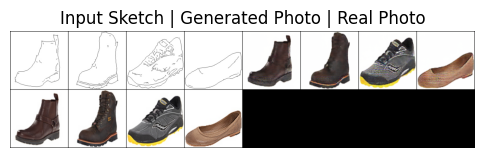

In [39]:
G.eval()

A, B = next(iter(loader))

A = A.to(device)
B = B.to(device)

with torch.no_grad():
    fake = G(A)

show_grid(
    torch.cat([
        A.cpu(),
        fake.cpu(),
        B.cpu()
    ], 0),
    title="Input Sketch | Generated Photo | Real Photo"
)